In [5]:
# Import library

import os 
import tensorflow as tf                 # library untuk deeplearning
import numpy as np                      # untuk array dll
import matplotlib.pyplot as plt         # untuk visualisasi grafik dll
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [6]:
# Declare variabel konstan


TRAIN_PATH = ('../data/Training/')
TEST_PATH = ('../data/Testing/')


# ResNet50 dilatih di ImageNet dengan ukuran 224x224, jadi kita ikuti ukuran itu
# (gambar MRI aslinya beda-beda ukuran, nanti otomatis di-resize)
img_rows = 224                          # height gambar
img_cols = 224                          # width gambar
IMG_SIZE = (img_rows, img_cols)

BATCH_SIZE = 32                         # kecilkan ke 16 kalau memori GPU habis
SEED = 42                               # biar hasil split selalu sama


print("Folder kerja:", os.getcwd())
print("Training ada?", os.path.isdir(TRAIN_PATH))
print("Isi:", os.listdir(TRAIN_PATH))     # harus muncul 4 nama kelas



Folder kerja: /Users/syamsaallam/Documents/Coding/deepLearning_aol/Brain-Tumor-MRI-Classification/notebooks
Training ada? True
Isi: ['pituitary', 'notumor', 'glioma', 'meningioma']


In [7]:
# Loading dataset

# Di ResNet50 semuanya dikerjakan image_dataset_from_directory:
#  - nama folder otomatis jadi label (urut alfabet)
#  - gambar otomatis di-resize ke IMG_SIZE
#  - label_mode='categorical' -> label langsung One-Hot Encode (setara to_categorical)
# Pembagian: folder Training dibagi 80% train : 20% validation,
#            folder Testing dipakai sebagai test.

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_PATH,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False,   # PENTING: jangan diacak supaya urutan prediksi cocok dengan label asli
)

classes = train_ds.class_names          # nama class dari nama foldernya
num_classes = len(classes)
print(classes)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
['glioma', 'meningioma', 'notumor', 'pituitary']


(32, 224, 224, 3)
(32, 4)


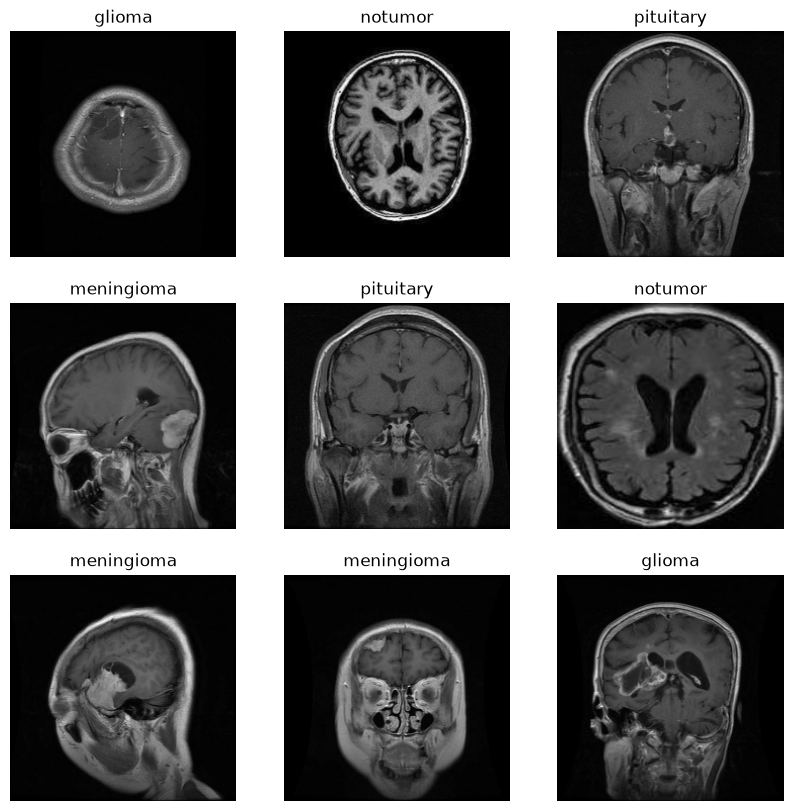

In [8]:
# Cek shape data & tampilkan beberapa gambar

for images, labels in train_ds.take(1):
    print(images.shape)                 # (32, 224, 224, 3) -> batch, height, width, RGB
    print(labels.shape)                 # (32, 4) -> one-hot 4 kelas

    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(classes[np.argmax(labels[i])])
        plt.axis("off")
    plt.show()

In [9]:
# Optimasi pipeline data
# prefetch = batch berikutnya disiapkan saat batch sekarang sedang ditraining
# (isi data tidak berubah, hanya lebih cepat)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
# Buat model ResNet50

# - Data augmentation : flip/rotasi/zoom acak, hanya aktif saat training
# - preprocess_input  : normalisasi khusus ResNet50 (pengganti / 255.0)
# - ResNet50(include_top=False): ambil bagian convolutional saja, bobot ImageNet
# - GlobalAveragePooling2D: pengganti Flatten(), parameter jauh lebih sedikit
# - Dense softmax     : 4 output untuk 4 jenis tumor


'''
# model1

data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.1),
        tf.keras.layers.RandomZoom(0.1),
    ],
    name="data_augmentation",
)
'''

'''
# Model2

data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.15),
        tf.keras.layers.RandomZoom(0.15),
        tf.keras.layers.RandomContrast(0.2),
        tf.keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
    ],
    name="data_augmentation",
)
'''


# Model3 dan Model4
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.1),
        tf.keras.layers.RandomZoom(0.1),
        tf.keras.layers.RandomContrast(0.2),
        tf.keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
    ],
    name="data_augmentation",
)

'''
# Model5
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.2),
        tf.keras.layers.RandomTranslation(0.1, 0.1),
        tf.keras.layers.RandomContrast(0.2),
        tf.keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
    ],
    name="data_augmentation",
)
'''

base_model = tf.keras.applications.ResNet50(
    include_top=False,                  # buang layer classifier bawaan (1000 kelas ImageNet)
    weights="imagenet",                 # pakai bobot hasil training ImageNet
    input_shape=(img_rows, img_cols, 3),
)

base_model.trainable = False            # tahap 1: bekukan dulu semua layer ResNet50

# Pakai Functional API (bukan Sequential seperti di DCNN) karena ada augmentasi + base model
inputs = tf.keras.Input(shape=(img_rows, img_cols, 3))
x = data_augmentation(inputs)
x = tf.keras.layers.Lambda(tf.keras.applications.resnet50.preprocess_input, name="preprocess")(x)
x = base_model(x, training=False)       # training=False agar BatchNorm tetap mode inference
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)     # dropout untuk mengurangi overfitting
x = tf.keras.layers.Dense(128, activation="relu")(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)   # softmax: multiclass

model = tf.keras.Model(inputs, outputs)
print(model.summary())

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 22s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

None


In [11]:
# Compile & training tahap 1 (feature extraction)
# Hanya layer baru (GlobalAvgPool -> Dense) yang dilatih, ResNet50 dibekukan.
# EarlyStopping: berhenti kalau val_loss tidak membaik 3 epoch, balik ke bobot terbaik.

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",    # sama seperti DCNN: multiclass, label one-hot
    metrics=["accuracy"],
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop],
)

Epoch 1/15


/Users/syamsaallam/Documents/Coding/deepLearning_aol/Brain-Tumor-MRI-Classification/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


140/140 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.7935 - loss: 0.5347 - val_accuracy: 0.8804 - val_loss: 0.3128
Epoch 2/15
  1/140 ━━━━━━━━━━━━━━━━━━━━ 2:21 1s/step - accuracy: 0.8750 - loss: 0.3384

KeyboardInterrupt: 

In [ ]:
# Training tahap 2 (fine-tuning)
# Buka 30 layer terakhir ResNet50 supaya menyesuaikan diri dengan citra MRI.
# BatchNorm tetap beku, learning rate dikecilkan (1e-5), WAJIB compile ulang.

base_model.trainable = True

for layer in base_model.layers:
    # hanya layer di blok conv4 dan conv5 yang dilatih, selain itu dibekukan
    layer.trainable = layer.name.startswith(("conv3_block", "conv4_block", "conv5_block"))

for layer in base_model.layers:         # BatchNorm tetap beku
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

# Model4
early_stop_2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

# Model3 (patience=2) dan Model4 (patience=3)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=[early_stop],
)

Epoch 1/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 63s 334ms/step - accuracy: 0.8849 - loss: 0.2991 - val_accuracy: 0.9411 - val_loss: 0.1694
Epoch 2/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 44s 314ms/step - accuracy: 0.9407 - loss: 0.1771 - val_accuracy: 0.9223 - val_loss: 0.2866
Epoch 3/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 45s 322ms/step - accuracy: 0.9411 - loss: 0.1643 - val_accuracy: 0.9161 - val_loss: 0.2499
Epoch 4/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 45s 316ms/step - accuracy: 0.9659 - loss: 0.1032 - val_accuracy: 0.9036 - val_loss: 0.3305
Epoch 5/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 45s 317ms/step - accuracy: 0.9746 - loss: 0.0765 - val_accuracy: 0.9536 - val_loss: 0.1947
Epoch 6/40
141/141 ━━━━━━━━━━━━━━━━━━━━ 45s 317ms/step - accuracy: 0.9737 - loss: 0.0771 - val_accuracy: 0.8661 - val_loss: 0.3968


In [ ]:
# Evaluation

score = model.evaluate(test_ds)
print(f"Test Loss: {score[0]}")
print(f"Test Accurate: {score[1]}")

51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 126ms/step - accuracy: 0.8933 - loss: 0.4390
Test Loss: 0.4390158951282501
Test Accurate: 0.8932584524154663


51/51 ━━━━━━━━━━━━━━━━━━━━ 10s 155ms/step


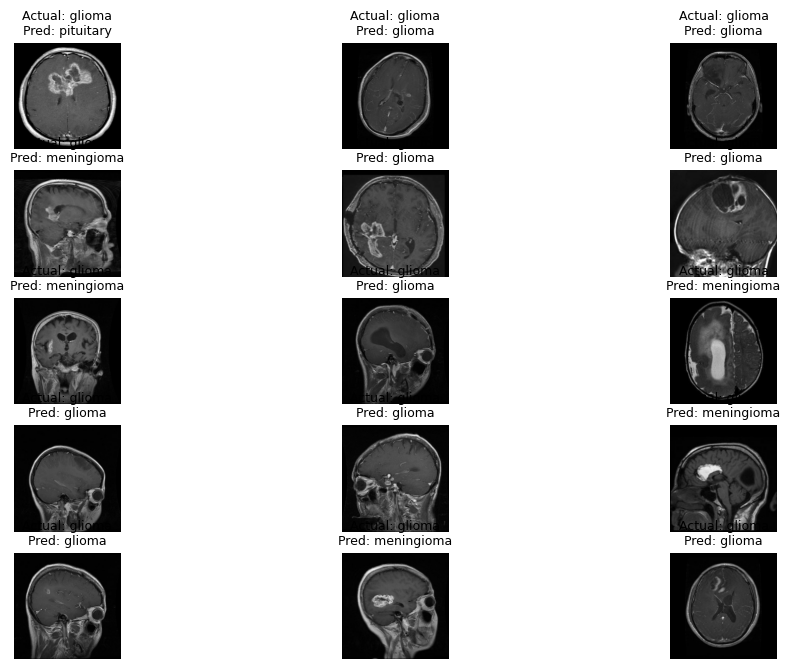

Actual: glioma | Predicted: pituitary
Actual: glioma | Predicted: glioma
Actual: glioma | Predicted: glioma
Actual: glioma | Predicted: meningioma
Actual: glioma | Predicted: glioma
Actual: glioma | Predicted: glioma
Actual: glioma | Predicted: meningioma
Actual: glioma | Predicted: glioma


In [ ]:
# Predictions

predictions = model.predict(test_ds)
predicted_label = np.argmax(predictions, axis=1)

# label asli dari test_ds (urutannya sama karena shuffle=False)
y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])

# tampilkan 8 gambar pertama beserta prediksinya
images_test, _ = next(iter(test_ds))
plt.figure(figsize=(12, 8))
for i in range(15):
    plt.subplot(5, 3, i + 1)
    plt.imshow(images_test[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"Actual: {classes[y_true[i]]}\nPred: {classes[predicted_label[i]]}", fontsize=9)
plt.show()

# jika cuman teks kaya predict dan actualnya
for i in range(8):
    print(f"Actual: {classes[y_true[i]]} | Predicted: {classes[predicted_label[i]]}")


              precision    recall  f1-score   support

      glioma       0.98      0.71      0.83       400
  meningioma       0.77      0.91      0.84       402
     notumor       0.97      0.97      0.97       400
   pituitary       0.91      0.97      0.94       400

    accuracy                           0.89      1602
   macro avg       0.90      0.89      0.89      1602
weighted avg       0.90      0.89      0.89      1602



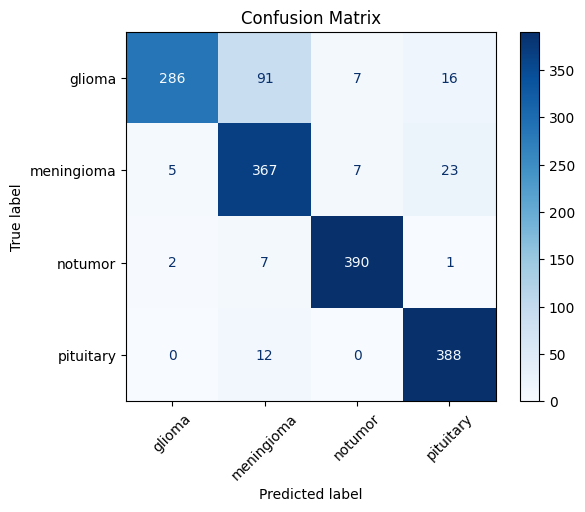

[0.9035714268684387, 0.9535714387893677, 0.8660714030265808]
[0.330488383769989, 0.194685697555542, 0.39684730768203735]


In [ ]:
# Classification report & confusion matrix
# Akurasi saja kurang untuk kasus medis, lihat juga precision/recall/f1 per kelas
# dan kelas mana yang sering tertukar (mis. glioma vs meningioma).

print(classification_report(y_true, predicted_label, target_names=classes))

cm = confusion_matrix(y_true, predicted_label)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()

print(history_ft.history["val_accuracy"][-3:])
print(history_ft.history["val_loss"][-3:])


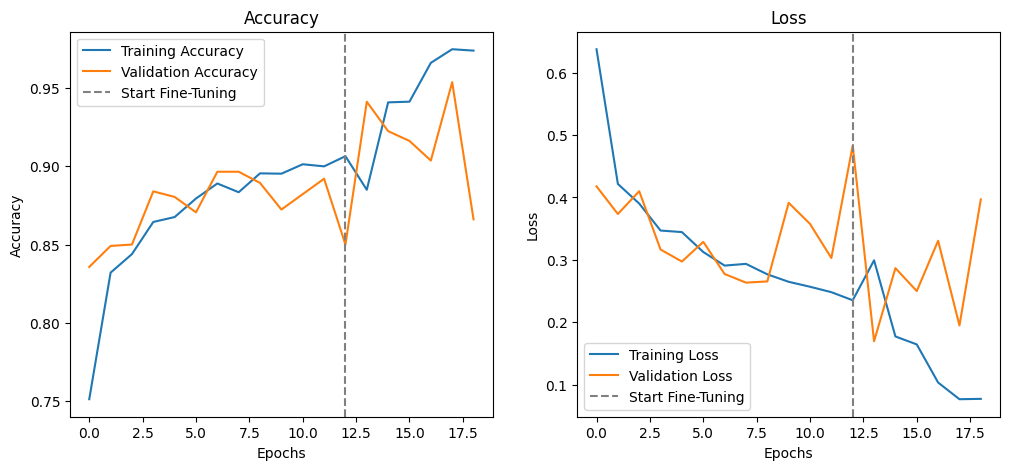

In [ ]:
# Visualization
# History tahap 1 & 2 digabung; garis putus-putus = awal fine-tuning

acc = history.history["accuracy"] + history_ft.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_ft.history["val_accuracy"]
loss = history.history["loss"] + history_ft.history["loss"]
val_loss = history.history["val_loss"] + history_ft.history["val_loss"]
start_ft = len(history.history["accuracy"])     # epoch awal fine-tuning

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axvline(start_ft - 1, linestyle="--", color="gray", label="Start Fine-Tuning")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(start_ft - 1, linestyle="--", color="gray", label="Start Fine-Tuning")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.show()

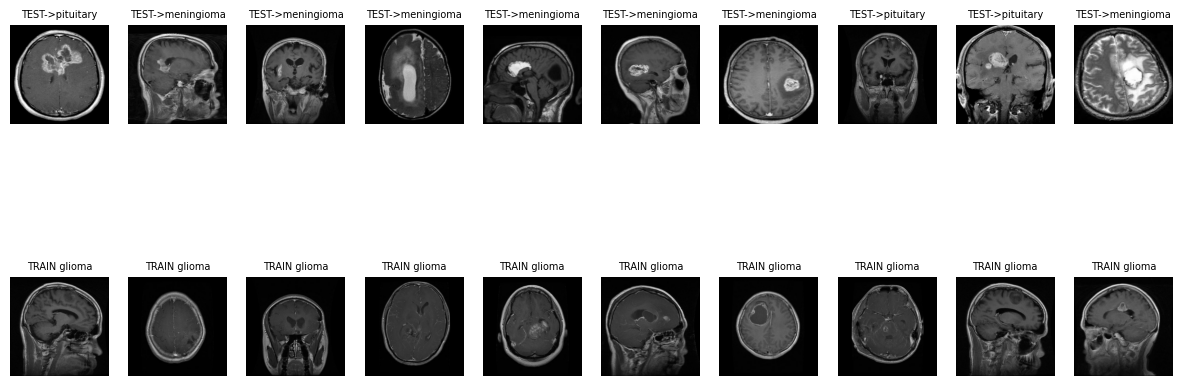

In [ ]:
# Diagnostik: kenapa glioma di test sering salah?
# Perhatikan apakah irisan MRI, zoom/crop, atau kontrasnya berbeda.

wrong, offset = [], 0
for imgs, _ in test_ds:
    for j in range(imgs.shape[0]):
        k = offset + j
        if y_true[k] == 0 and predicted_label[k] != 0 and len(wrong) < 10:
            wrong.append((imgs[j].numpy().astype("uint8"), classes[predicted_label[k]]))
    offset += imgs.shape[0]

train_gl = []
for imgs, labs in train_ds.take(20):
    for j in range(imgs.shape[0]):
        if np.argmax(labs[j]) == 0 and len(train_gl) < 10:
            train_gl.append(imgs[j].numpy().astype("uint8"))

plt.figure(figsize=(15, 6))
for i, (img, pred) in enumerate(wrong):
    plt.subplot(2, 10, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"TEST->{pred}", fontsize=7)
for i, img in enumerate(train_gl):
    plt.subplot(2, 10, 11 + i)
    plt.imshow(img)
    plt.axis("off")
    plt.title("TRAIN glioma", fontsize=7)
plt.show()

In [ ]:
# Simpan model

model.save("resnet50_brain_tumor_Model5.keras")

'''
Model1 :
  batch_size=32,
  early_stop patience = 5,
  train1 = epochs 30,
  train2 = epoch 10,
  ubah data augmentation


Model2 :
  dropout= 0.5,
  batch_size=64,
  early_stop patience = 4,
  train1 = epochs 15,
  train2 = epoch 30,
  ubah data_augmentation

Model3 :
  dropout= 0.3,
  batch_size=32,
  early_stop patience = 5,
  train1 = epochs 15,
  train2 = epoch 30, learning rate = 0.0001, ada reduce_lr (patience=2)

Model4 :
  dropout= 0.3,
  batch_size=32,
  train2 = tambahkan "conv3_block"
  buat early_stop2 patience = 5, di train2
  train1 = epochs 15,
  train2 = epoch 40, learning rate = 5e-5, ada reduce_lr (patience=3) dan early stop baru

  "INI PALING BETTER UDAH STRES"

Model5 :
  cuman mengubah data augmentation,
  lainnya tetap sama seperti model4

'''


'\nModel1 :\n  batch_size=32, \n  early_stop patience = 5, \n  train1 = epochs 30, \n  train2 = epoch 10,\n  ubah data augmentation\n\n\nModel2 :\n  dropout= 0.5, \n  batch_size=64, \n  early_stop patience = 4, \n  train1 = epochs 15, \n  train2 = epoch 30, \n  ubah data_augmentation\n\nModel3 :\n  dropout= 0.3, \n  batch_size=32, \n  early_stop patience = 5, \n  train1 = epochs 15, \n  train2 = epoch 30, learning rate = 0.0001, ada reduce_lr (patience=2)\n\nModel4 :\n  dropout= 0.3, \n  batch_size=32, \n  train2 = tambahkan "conv3_block"\n  buat early_stop2 patience = 5, di train2\n  train1 = epochs 15, \n  train2 = epoch 40, learning rate = 5e-5, ada reduce_lr (patience=3) dan early stop baru\n'